**importing libraries**

In [7]:
import pandas as pd
import matplotlib.pyplot
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.dates as mdates

**loading dataframe**

In [8]:
df = pd.read_parquet("../data/combined_all.parquet")

**lists**

In [9]:
month_order = ["January","February","March","April","May","June","July","August","September","October","November","December"]

**uk monthly revenue**

In [10]:
uk_revenue = df[df["country"] == "united kingdom"].groupby(["year","country","month"]).agg(
    net_revenue = ("net_sales","sum"),
    volume = ("quantity","sum"),
    orders = ("invoice","nunique")
).reset_index().round(2)
uk_revenue["month"] = pd.Categorical(uk_revenue["month"],categories=month_order,ordered=True)
uk_revenue = uk_revenue.sort_values(by=["year","month"])
uk_revenue["aov"] = (uk_revenue["net_revenue"] / uk_revenue["orders"]).round(2)
uk_revenue["revenue_growth_rate"] = (uk_revenue["net_revenue"].pct_change() * 100).round(2)
uk_revenue["volume_growth_rate"] = (uk_revenue["volume"].pct_change() * 100).round(2)
uk_revenue["orders_growth_rate"] = (uk_revenue["orders"].pct_change() * 100).round(2)
uk_revenue["aov_growth_rate"] = (uk_revenue["aov"].pct_change() * 100).round(2)
uk_revenue

,year,country,month,net_revenue,volume,orders,aov,revenue_growth_rate,volume_growth_rate,orders_growth_rate,aov_growth_rate
0,2009,united kingdom,December,727655.96,382208,2198,331.05,NaN,NaN,NaN,NaN
5,2010,united kingdom,January,491108.70,242215,1481,331.61,-32.51,-36.63,-32.62,0.17
4,2010,united kingdom,February,444249.84,232808,1825,243.42,-9.54,-3.88,23.23,-26.59
8,2010,united kingdom,March,676956.67,368775,2188,309.40,52.38,58.40,19.89,27.11
1,2010,united kingdom,April,497154.19,288660,1752,283.76,-26.56,-21.72,-19.93,-8.29
9,2010,united kingdom,May,520678.69,306285,2274,228.97,4.73,6.11,29.79,-19.31
7,2010,united kingdom,June,581661.63,329072,2068,281.27,11.71,7.44,-9.06,22.84
6,2010,united kingdom,July,489766.17,256622,1859,263.46,-15.80,-22.02,-10.11,-6.33
2,2010,united kingdom,August,561260.65,311634,1745,321.64,14.60,21.44,-6.13,22.08
12,2010,united kingdom,September,726528.31,479889,2143,339.02,29.45,53.99,22.81,5.40


**yearly sales**

In [11]:
yearly_revenue = df[df["country"] == "united kingdom"].groupby(["year","country"]).agg(
    net_revenue = ("net_sales","sum"),
    volume = ("quantity","sum"),
    orders = ("invoice","nunique")
).reset_index().round(2)
yearly_revenue

,year,country,net_revenue,volume,orders
0,2009,united kingdom,727655.96,382208,2198
1,2010,united kingdom,7799881.95,4197005,25301
2,2011,united kingdom,7511063.74,3965728,21609


**charts**

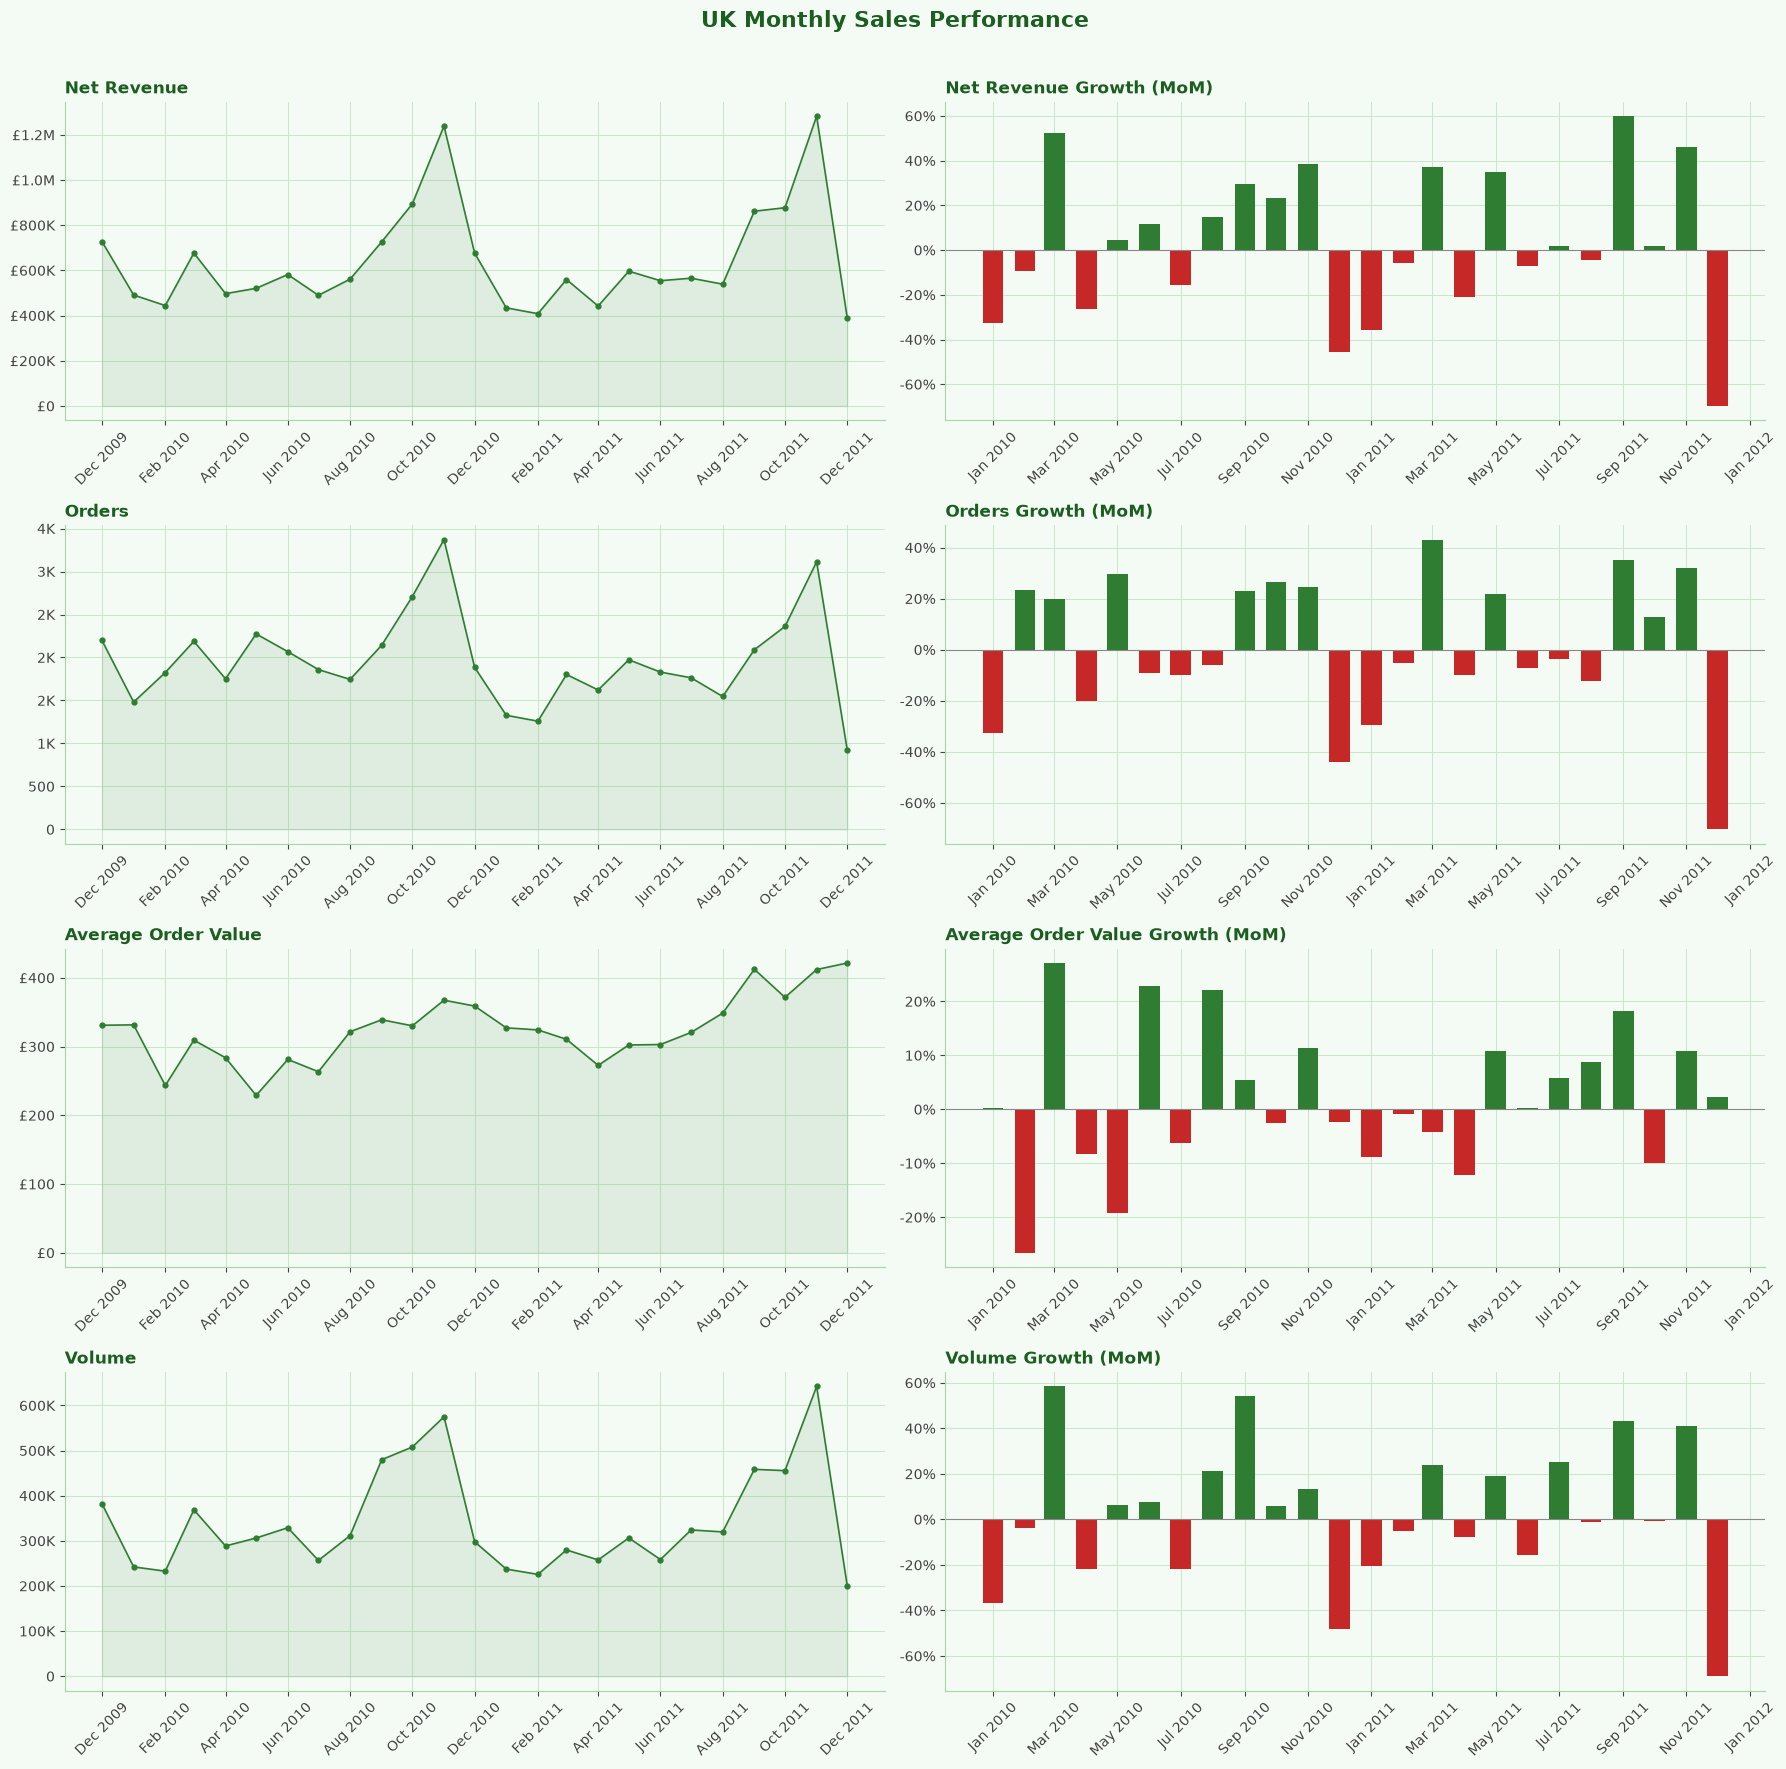

In [12]:
uk_revenue = uk_revenue.reset_index(drop=True)
uk_revenue["period"] = pd.to_datetime(
    uk_revenue["year"].astype(str) + "-" + uk_revenue["month"].astype(str),
    format="%Y-%B"
)

dark, mid, neg, bg = "#1B5E20", "#2E7D32", "#C62828", "#F4FAF4"

def gbp(x, _):
    if abs(x) >= 1e6: return f"£{x/1e6:.1f}M"
    if abs(x) >= 1e3: return f"£{x/1e3:.0f}K"
    return f"£{x:,.0f}"

def num(x, _):
    if abs(x) >= 1e6: return f"{x/1e6:.1f}M"
    if abs(x) >= 1e3: return f"{x/1e3:.0f}K"
    return f"{x:,.0f}"

pct = lambda x, _: f"{x:.0f}%"

metrics = [
    ("net_revenue", "revenue_growth_rate", "Net Revenue", gbp),
    ("orders", "orders_growth_rate", "Orders", num),
    ("aov", "aov_growth_rate", "Average Order Value", gbp),
    ("volume", "volume_growth_rate", "Volume", num),
]

fig, axes = plt.subplots(4, 2, figsize=(18, 18), facecolor=bg)

for row, (col, gcol, title, fmt) in zip(axes, metrics):
    ax, bx = row

    ax.plot(uk_revenue["period"], uk_revenue[col],
            color=mid, linewidth=1.2, marker="o", markersize=3.5)
    ax.fill_between(uk_revenue["period"], uk_revenue[col], color=mid, alpha=0.10)
    ax.set_title(title, fontsize=12, fontweight="bold", color=dark, loc="left")
    ax.yaxis.set_major_formatter(FuncFormatter(fmt))

    colors = [mid if v >= 0 else neg for v in uk_revenue[gcol].fillna(0)]
    bx.bar(uk_revenue["period"], uk_revenue[gcol], width=20, color=colors)
    bx.axhline(0, color="#888", linewidth=0.8)
    bx.set_title(f"{title} Growth (MoM)", fontsize=12, fontweight="bold",
                 color=dark, loc="left")
    bx.yaxis.set_major_formatter(FuncFormatter(pct))

    for a in (ax, bx):
        a.set_facecolor(bg)
        a.grid(True, color="#C8E6C9", linewidth=0.7)
        a.set_axisbelow(True)
        for s in ["top", "right"]:
            a.spines[s].set_visible(False)
        for s in ["left", "bottom"]:
            a.spines[s].set_color("#A5D6A7")
        a.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
        a.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
        a.tick_params(axis="x", rotation=45, colors="#444")
        a.tick_params(axis="y", colors="#444")

fig.suptitle("UK Monthly Sales Performance", fontsize=16,
             fontweight="bold", color=dark)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()